# FPMarkets — Exploratory Data Analysis

Goal: gradually clean the FP Markets copy-trading leaders down to the ones worth copying, understanding along the way who they are and how they trade, before `03_strategy_metrics.ipynb` computes the strategy metrics and ranks them.

Input: `analysis/data/fpmarkets_clean.pkl`, the output of `01_data_quality.ipynb`. That notebook already parsed every field used here: the monthly return series, the leverage summaries, the flat `ts_*` trade statistics, the normalized instruments and asset classes, and the activity and trade-count columns.

Each cut follows the same pattern: **identify** a group of uninteresting traders (and show why), then **drop** it. Every later section only sees the traders that are left, and only those are exported to 03, so 03 doesn't need to filter them again.

Sections:
1. New, untraded and ruined accounts
2. Track record length
3. Activity
4. Returns and drawdown
5. Cleaned universe
6. Trading style: frequency and trade duration
7. Win rate vs payoff
8. Instruments and asset classes
9. Leverage
10. Monthly returns over calendar time
11. Account currency
12. How the metrics relate to each other
13. Summary and further analysis
14. Export

In [1]:
import json
import sys
from pathlib import Path

REPO_ROOT = Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from analysis.shared import performance_metrics as pm
from analysis.shared import plot_style as ps

ps.apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

DATA_DIR = Path("../data")

### Bounds

Personal selection criteria. Traders who don't meet them are dropped in §2-4: a minimum track record, a maximum tolerable drawdown, ruin, and how recently an account must have traded to count as active.

In [2]:
MIN_AGE_DAYS = 180
MAX_DRAWDOWN_LIMIT = 30
RUIN_DRAWDOWN_PCT = 95.0
ACTIVE_LOOKBACK_MONTHS = 3

### Load data

Load the cleaned pickle from 01. Every column already has its final type, including the per-trader monthly return series. `drop()` removes a group of traders and records how many are left, for the funnel in §5.

In [3]:
IN_PKL = DATA_DIR / "fpmarkets_clean.pkl"
OUT_PKL = DATA_DIR / "fpmarkets_flagged.pkl"  # read by 03
OUT_CSV = DATA_DIR / "fpmarkets_flagged.csv"  # same data, for opening without pandas

df = pd.read_pickle(IN_PKL)
SNAPSHOT = df["scraped_at"].max().to_period("M")
print(f"{len(df)} traders, snapshot month {SNAPSHOT}, scraped {df['scraped_at'].min():%Y-%m-%d} to {df['scraped_at'].max():%Y-%m-%d}")

funnel = [("Scraped", len(df))]


def drop(frame: pd.DataFrame, remove: pd.Series, step: str) -> pd.DataFrame:
    """Drop the traders flagged by `remove` and record how many are left after `step`."""
    kept = frame[~remove].reset_index(drop=True)
    funnel.append((step, len(kept)))
    print(f"Dropped {int(remove.sum())} traders; {len(kept)} remain.")
    return kept

2127 traders, snapshot month 2026-09, scraped 2026-09-11 to 2026-09-12


## 1. New, untraded and ruined accounts

### Filter out new traders

320 traders have no track record at all (`age_days == 0`): no monthly returns and `-` placeholders in every return window (see 01). There's nothing to evaluate for these accounts, so they're dropped rather than flagged.

In [4]:
df = drop(df, df["age_days"] == 0, "Has a track record")
# Only brand-new accounts lacked a monthly series, so the month count is whole again.
df["months_since_active"] = df["months_since_active"].astype(int)

Dropped 320 traders; 1807 remain.


### Flags

Flags the cuts below are based on. They stay in the export, so 03 can still read them (after cleaning they're the same for every trader):
- `has_trades`: the account has at least one trade. Some accounts have a monthly chart but never traded, so they have no `trade_statistics`.
- `is_ruined`: site max drawdown ≥ 95%. That leaves too little equity for any later % return to mean anything (see below).
- `months_since_trade` / `is_active`: months since the last complete month with a **non-zero** return; an account is active if it had one in the last 3 complete months (§3).
- `style_tier`: trading frequency (`trades_per_day` from 01) in tiers of < 1, 1-5, 5-10, 10-15 and 15+ trades a day.

Three columns used throughout this notebook are added too: annualized return (CAGR), win rate and payoff ratio.

In [5]:
STYLE_BINS = [0, 1, 5, 10, 15, np.inf]
STYLE_LABELS = ["<1/day", "1-5/day", "5-10/day", "10-15/day", "15+/day"]


def months_since_trade(returns: pd.Series) -> float:
    """Months between the snapshot and the last complete month with a non-zero return (NaN if none)."""
    traded = returns[(returns.index < SNAPSHOT) & (returns != 0)]
    return (SNAPSHOT - traded.index.max()).n if len(traded) else np.nan


df["has_trades"] = df["total_instrument_trades"] > 0
df["is_ruined"] = df["trading_max_drawdown"] >= RUIN_DRAWDOWN_PCT
df["months_since_trade"] = df["monthly_returns"].apply(months_since_trade)
df["is_active"] = df["months_since_trade"] <= ACTIVE_LOOKBACK_MONTHS
df["style_tier"] = pd.cut(df["trades_per_day"], STYLE_BINS, labels=STYLE_LABELS, right=False)

# Analysis helpers for this notebook only; 03 computes its own versions, so they're not exported.
HELPER_COLUMNS = ["cagr_pct", "win_rate", "payoff_ratio"]
df["cagr_pct"] = [100 * pm.cagr(r / 100, d) for r, d in zip(df["return_total"], df["age_days"])]
df["win_rate"] = df["ts_trades_won"] / df["closed_trades"]
df["payoff_ratio"] = df["ts_avg_win"] / df["ts_avg_loss"].abs()

print(f"No trades: {(~df['has_trades']).sum()}, ruined: {df['is_ruined'].sum()}, inactive: {(~df['is_active']).sum()}")

No trades: 55, ruined: 665, inactive: 848


### Filter out accounts with no trades

These accounts have a monthly chart but no closed trades at all (no `trade_statistics`), so there's nothing to evaluate.

In [6]:
df = drop(df, ~df["has_trades"], "Has trades")

Dropped 55 traders; 1752 remain.


### Filter out ruined accounts

#### Post-ruin return artifacts

Why ruined accounts are meaningless: once an account has lost ~99.9%, the site keeps computing % returns on the remaining few cents. A +300% month on 0.02% of the starting balance is still only 0.08% of it. Those artifacts show up in the short return windows (`return_quarter`, `return_month`), which is also what the site sorts its leaderboard by, so they rise to the top of it.

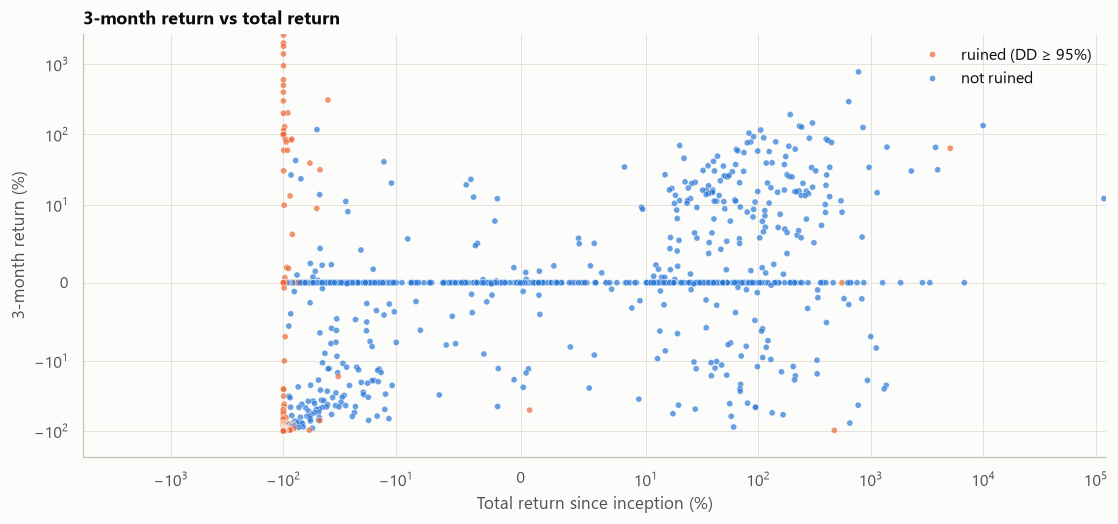

Ruined accounts with a 3-month return above +100%: 14 of 562


In [7]:
artifact = df[["return_total", "return_quarter", "is_ruined"]].dropna().copy()
artifact["status"] = np.where(artifact["is_ruined"], "ruined (DD ≥ 95%)", "not ruined")

fig, ax = plt.subplots(figsize=(12, 5))
sns.scatterplot(data=artifact, x="return_total", y="return_quarter", hue="status",
                palette={"not ruined": ps.PRIMARY, "ruined (DD ≥ 95%)": ps.HIGHLIGHT}, s=16, alpha=0.7, ax=ax)
ax.set_xscale("symlog", linthresh=10)
ax.set_yscale("symlog", linthresh=10)
ax.set_title("3-month return vs total return")
ax.set_xlabel("Total return since inception (%)")
ax.set_ylabel("3-month return (%)")
ax.legend(title="")
plt.show()

ruined_q = artifact.loc[artifact["is_ruined"], "return_quarter"]
print(f"Ruined accounts with a 3-month return above +100%: {(ruined_q > 100).sum()} of {len(ruined_q)}")

#### What predicts ruin

Before dropping them, the one thing ruined accounts can still teach a copier: what they had in common. A leader who is profitable today with a low drawdown can still blow up later, so traits that came with ruin across the whole universe are warning signs to score in 03. Leverage (from 01, on days with open exposure) is split into quintiles; trading frequency uses `style_tier`.

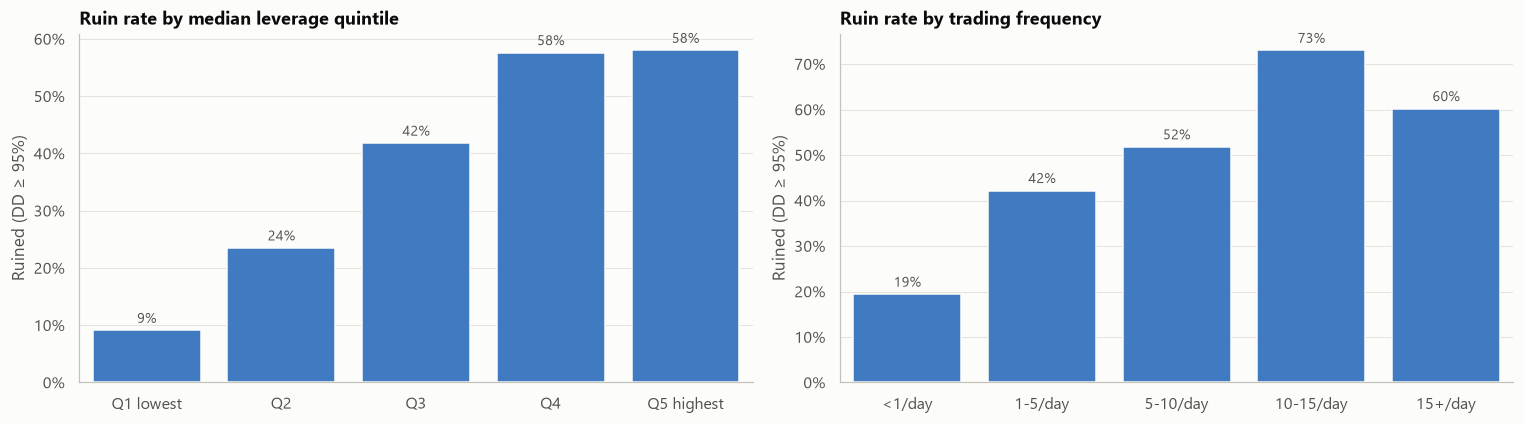

,leverage_range,traders,ruined_pct
lev_median,,,
Q1 lowest,0.2-12x,350,9.1
Q2,12.0-34x,349,23.5
Q3,33.8-99x,349,41.8
Q4,99.0-511x,349,57.6
Q5 highest,"512.0-1,391,548x",350,58.0


,traders,ruined_pct
style_tier,,
<1/day,650,19.4
1-5/day,656,42.2
5-10/day,224,51.8
10-15/day,89,73.0
15+/day,133,60.2


In [8]:
LEV_QUINTILES = ["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]
with_lev = df[df["lev_median"] > 0]
lev_quintile = pd.qcut(with_lev["lev_median"], 5, labels=LEV_QUINTILES)
ruin_by_lev = with_lev.groupby(lev_quintile, observed=True).agg(
    leverage_range=("lev_median", lambda s: f"{s.min():.1f}-{s.max():,.0f}x"),
    traders=("trader_id", "size"),
    ruined_pct=("is_ruined", lambda s: 100 * s.mean()),
).round(1)
ruin_by_style = df.groupby("style_tier", observed=True).agg(
    traders=("trader_id", "size"),
    ruined_pct=("is_ruined", lambda s: 100 * s.mean()),
).reindex(STYLE_LABELS).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, table, title in [(axes[0], ruin_by_lev, "Ruin rate by median leverage quintile"),
                         (axes[1], ruin_by_style, "Ruin rate by trading frequency")]:
    sns.barplot(x=table.index.astype(str), y=table["ruined_pct"], color=ps.PRIMARY, ax=ax)
    ps.label_bars(ax, fmt="{:.0f}%")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(f"Ruined (DD ≥ {RUIN_DRAWDOWN_PCT:.0f}%)")
    ax.yaxis.set_major_formatter(ps.percent_formatter)
plt.tight_layout()
plt.show()
display(ruin_by_lev)
ruin_by_style

**Insights:**
- Leverage is the clearest ruin predictor: **9%** of the lowest-leverage quintile (≤ 12x median) is ruined, against **58%** of the two highest quintiles (> 99x). The arrow points both ways, because a collapsing balance also inflates leverage, but p95 leverage stays a useful risk input in 03.
- Ruin rises with trading frequency too: **19%** of traders doing < 1 trade a day are ruined, versus 42% at 1-5 a day and **60-73%** above 10 a day.
- 664 of the 1,752 accounts that have traded (38%) are ruined, by far the biggest single cut.

In [9]:
df = drop(df, df["is_ruined"], f"Not ruined (DD < {RUIN_DRAWDOWN_PCT:.0f}%)")

Dropped 664 traders; 1088 remain.


## 2. Track record length

`age_days` is exact (days since the account started), so it can be bucketed precisely. Accounts younger than `MIN_AGE_DAYS` are dropped: short windows annualize into meaningless numbers, and in the full universe most blow-ups happen in the first months.

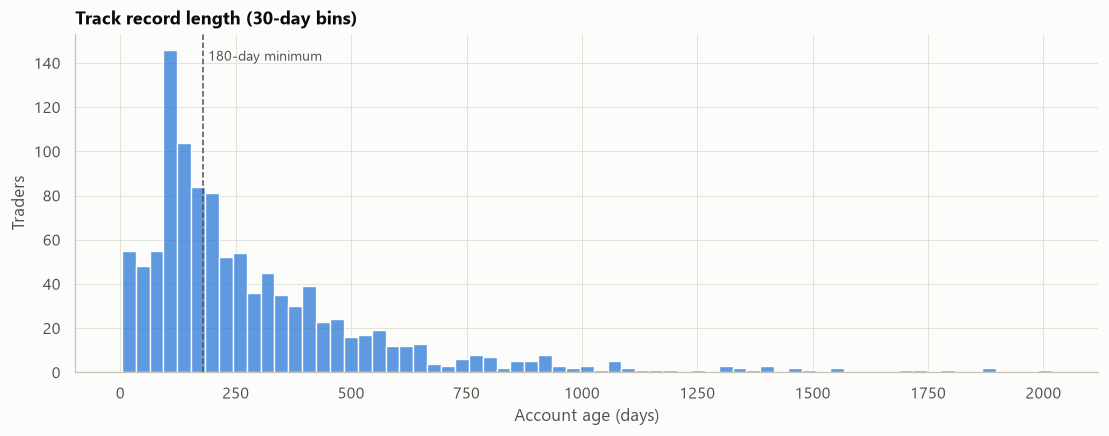

Median age: 200 days


,traders
age_days,
<3 mo,152
3-6 mo,335
6-12 mo,308
1-1.5 y,149
1.5-2 y,64
2 y+,80


In [10]:
age_buckets = pd.cut(df["age_days"], [0, 90, 180, 365, 545, 730, np.inf],
                     labels=["<3 mo", "3-6 mo", "6-12 mo", "1-1.5 y", "1.5-2 y", "2 y+"], right=False)

fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=df, x="age_days", binwidth=30, color=ps.PRIMARY, ax=ax)
ax.axvline(MIN_AGE_DAYS, color=ps.INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(MIN_AGE_DAYS + 10, ax.get_ylim()[1] * 0.92, f"{MIN_AGE_DAYS}-day minimum", color=ps.INK_SECONDARY, fontsize=9)
ax.set_title("Track record length (30-day bins)")
ax.set_xlabel("Account age (days)")
ax.set_ylabel("Traders")
plt.show()
print(f"Median age: {df['age_days'].median():.0f} days")
age_buckets.value_counts().sort_index().to_frame("traders")

**Insights:**
- Among the 1,088 non-ruined accounts the median age is **200 days**, and 487 of them (45%) are younger than 180 days. Only 144 (13%) have more than 1.5 years of history.
- Longer minimums (1 year+) would leave too few candidates to rank, so 03 keeps 180 days and splits the result into established (1 year+) leaders and a watchlist instead.

In [11]:
df = drop(df, df["age_days"] < MIN_AGE_DAYS, f"Age ≥ {MIN_AGE_DAYS} days")

Dropped 487 traders; 601 remain.


## 3. Activity

An account is active if it had a **non-zero** monthly return in one of the last 3 complete months. The site keeps adding 0% months to the chart of an account that has stopped trading, so "has a recent monthly return" (`months_since_active` from 01) would count idle accounts as active. The daily leverage chart confirms it: leaders whose last 3 months are all exactly 0% had open positions on a median of 0 of the last 90 days. The snapshot month is left out because only a few days of it had elapsed. Copying an idle account gets you nothing, so inactive accounts are dropped.

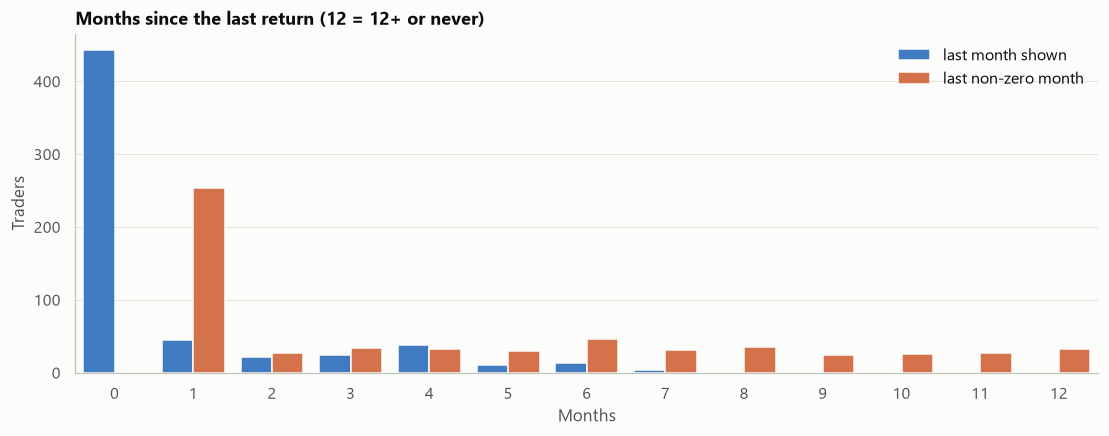

Inactive (no non-zero return in the last 3 complete months): 286 of 601 traders
  still shown with a recent (0%) month on the site: 173


In [12]:
# The site pads idle accounts with 0% months: compare the last month shown with the last month with a non-zero return.
idle_gap = pd.concat([
    pd.DataFrame({"months": df["months_since_active"].clip(upper=12), "measure": "last month shown"}),
    pd.DataFrame({"months": df["months_since_trade"].fillna(12).clip(upper=12).astype(int), "measure": "last non-zero month"}),
])
fig, ax = plt.subplots(figsize=(12, 4))
sns.countplot(data=idle_gap, x="months", hue="measure", palette=ps.SERIES[:2], ax=ax)
ax.set_title("Months since the last return (12 = 12+ or never)")
ax.set_xlabel("Months")
ax.set_ylabel("Traders")
ax.legend(title="")
plt.show()

inactive = ~df["is_active"]
padded = inactive & (df["months_since_active"] <= 1)
print(f"Inactive (no non-zero return in the last {ACTIVE_LOOKBACK_MONTHS} complete months): {inactive.sum()} of {len(df)} traders")
print(f"  still shown with a recent (0%) month on the site: {padded.sum()}")

**Insights:**
- **286 of the 601 remaining accounts (48%)** had no non-zero return in the last 3 complete months, so copying them now gets you nothing.
- The site hides this: 173 of these idle accounts still show a 0% month for August or September. Going by the last month shown (blue), most accounts look current. Going by the last month with a non-zero return (orange), activity spreads out over the past year. This is why `is_active` uses the last non-zero month.

In [13]:
df = drop(df, ~df["is_active"], f"Traded in the last {ACTIVE_LOOKBACK_MONTHS} complete months")

Dropped 286 traders; 315 remain.


## 4. Returns and drawdown

### Total return

`return_total` spans several orders of magnitude, so a plain histogram would be unreadable. Bucketing it shows the shape honestly, with losses in red and gains in blue. Traders who have lost money since inception aren't worth copying, so they're dropped (`return_total > 0` is kept).

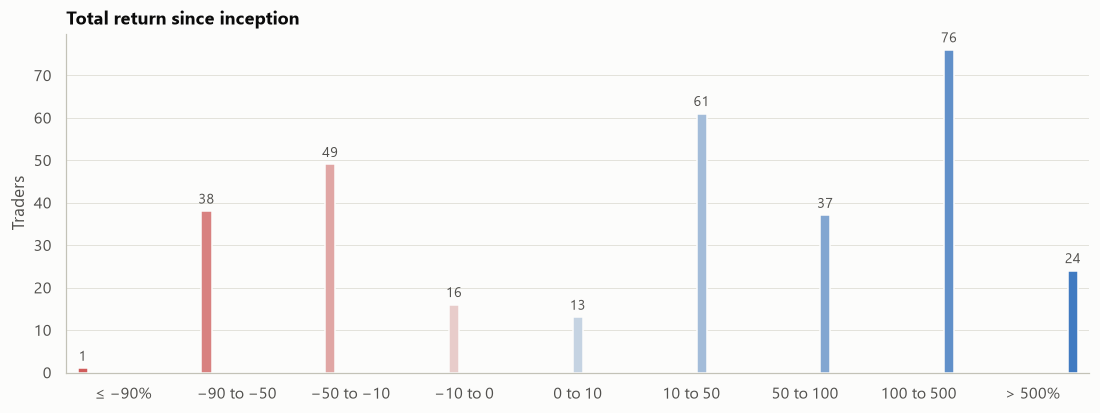

Median total return: 36.2%
Profitable traders: 67.0%


In [14]:
return_edges = [-100.01, -90, -50, -10, 0, 10, 50, 100, 500, np.inf]
return_labels = ["≤ −90%", "−90 to −50", "−50 to −10", "−10 to 0", "0 to 10", "10 to 50", "50 to 100", "100 to 500", "> 500%"]
df["return_bucket"] = pd.cut(df["return_total"], return_edges, labels=return_labels)

# Diverging: losses in red, gains in blue, intensity by distance from zero.
bucket_colors = [ps.DIVERGING_CMAP(x) for x in np.r_[np.linspace(0.0, 0.38, 4), np.linspace(0.62, 1.0, 5)]]
fig, ax = plt.subplots(figsize=(12, 4))
sns.countplot(data=df, x="return_bucket", hue="return_bucket", order=return_labels,
              palette=dict(zip(return_labels, bucket_colors)), legend=False, ax=ax)
ps.label_bars(ax)
ax.set_title("Total return since inception")
ax.set_xlabel("")
ax.set_ylabel("Traders")
plt.show()

print(f"Median total return: {df['return_total'].median():.1f}%")
print(f"Profitable traders: {(df['return_total'] > 0).mean():.1%}")

**Insights:**
- Once ruined, young and idle accounts are gone, the picture is much better than for the whole leaderboard: the median total return is **+36%** and **67%** of the 315 remaining traders are profitable.
- The other 104 lost money since inception and are dropped.

In [15]:
df = drop(df, df["return_total"] <= 0, "Positive total return")

Dropped 104 traders; 211 remain.


### Maximum drawdown

The site-reported max drawdown, followed by the risk/return map: annualized return (CAGR, from `return_total` and `age_days`) against max drawdown. The y-axis is clipped at 10,000% so a handful of extreme accounts don't flatten everything else. The shaded box is the selection zone, drawdown ≤ 30%. Traders outside it are dropped.

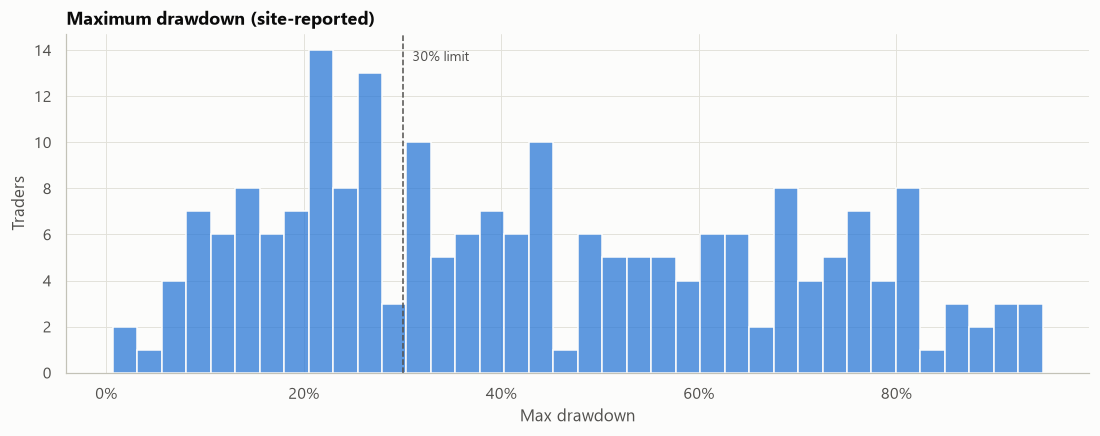

,count,mean,std,min,10%,25%,50%,75%,90%,max
trading_max_drawdown,211.0,43.4,24.5,0.7,13.5,22.5,39.3,63.6,78.8,94.8


In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=df, x="trading_max_drawdown", binwidth=2.5, color=ps.PRIMARY, ax=ax)
ax.axvline(MAX_DRAWDOWN_LIMIT, color=ps.INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(MAX_DRAWDOWN_LIMIT + 1, ax.get_ylim()[1] * 0.92, f"{MAX_DRAWDOWN_LIMIT}% limit", color=ps.INK_SECONDARY, fontsize=9)
ax.set_title("Maximum drawdown (site-reported)")
ax.set_xlabel("Max drawdown")
ax.xaxis.set_major_formatter(ps.percent_formatter)
ax.set_ylabel("Traders")
plt.show()
df["trading_max_drawdown"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_frame().T

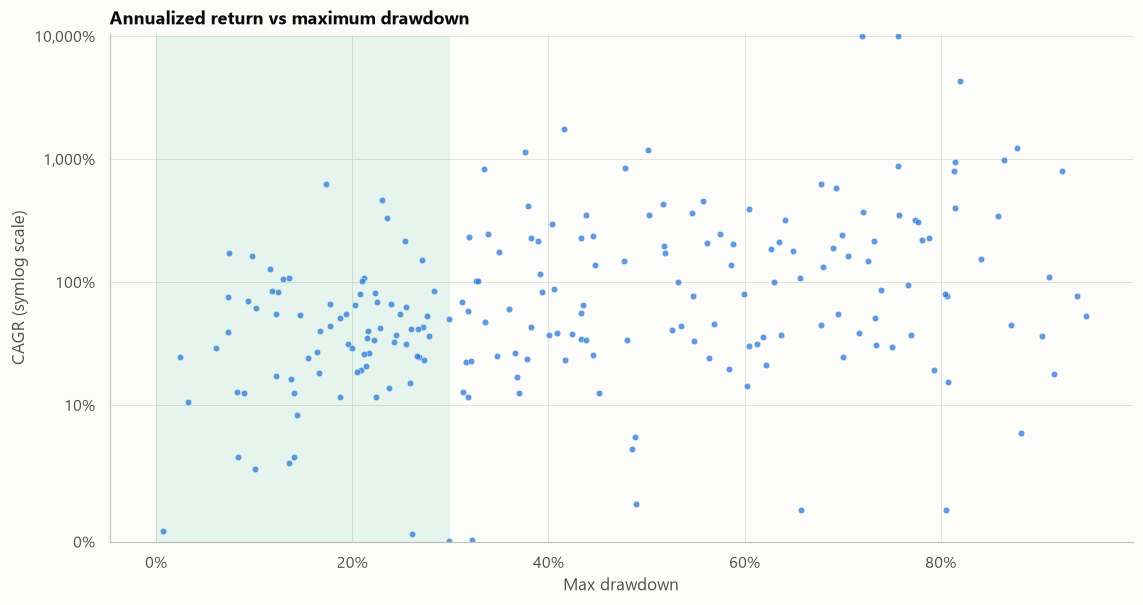

,size,median
trading_max_drawdown,,
"[0, 10)",12,26.9
"[10, 20)",26,41.9
"[20, 30)",41,39.8
"[30, 40)",27,60.0
"[40, 60)",43,80.0
"[60, 80)",42,139.6
"[80, 95)",20,94.7


In [17]:
risk_map = df.assign(**{"CAGR (%)": df["cagr_pct"].clip(upper=10_000)})

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between([0, MAX_DRAWDOWN_LIMIT], 0, 10_000, color=ps.SERIES[2], alpha=0.10, linewidth=0)
sns.scatterplot(data=risk_map, x="trading_max_drawdown", y="CAGR (%)", color=ps.PRIMARY, s=18, alpha=0.75, ax=ax)
ax.set_yscale("symlog", linthresh=10)
ax.set_ylim(bottom=0)  # losing traders were dropped above
ax.set_title("Annualized return vs maximum drawdown")
ax.set_xlabel("Max drawdown")
ax.set_ylabel("CAGR (symlog scale)")
ax.xaxis.set_major_formatter(ps.percent_formatter)
ax.yaxis.set_major_formatter(ps.percent_formatter)
plt.show()

dd_bins = pd.cut(df["trading_max_drawdown"], [0, 10, 20, 30, 40, 60, 80, 95], right=False)
df.groupby(dd_bins, observed=True)["cagr_pct"].agg(["size", "median"]).round(1)

**Insights:**
- Among profitable, mature, active traders, more drawdown **does** come with more return: median CAGR goes from about +40% a year at 10-30% drawdown to +60% at 30-40%, +80% at 40-60% and +140% at 60-80%.
- That's survivorship, not a reason to accept more risk. §1 showed how often accounts at these risk levels blow up, and the traders here are the ones that happened to come back. A 30% drawdown needs +43% to recover, while a 60% one needs +150%. The 30% limit is a risk tolerance, not the point where returns peak.
- 132 of the 211 profitable traders (63%) have a max drawdown above 30% and are dropped.

In [18]:
df = drop(df, df["trading_max_drawdown"] > MAX_DRAWDOWN_LIMIT, f"Max drawdown ≤ {MAX_DRAWDOWN_LIMIT}%")

Dropped 132 traders; 79 remain.


## 5. Cleaned universe

How many leaders were left after each cut in §1-4. Every section from here on, and 03, works on the traders in the last bar.

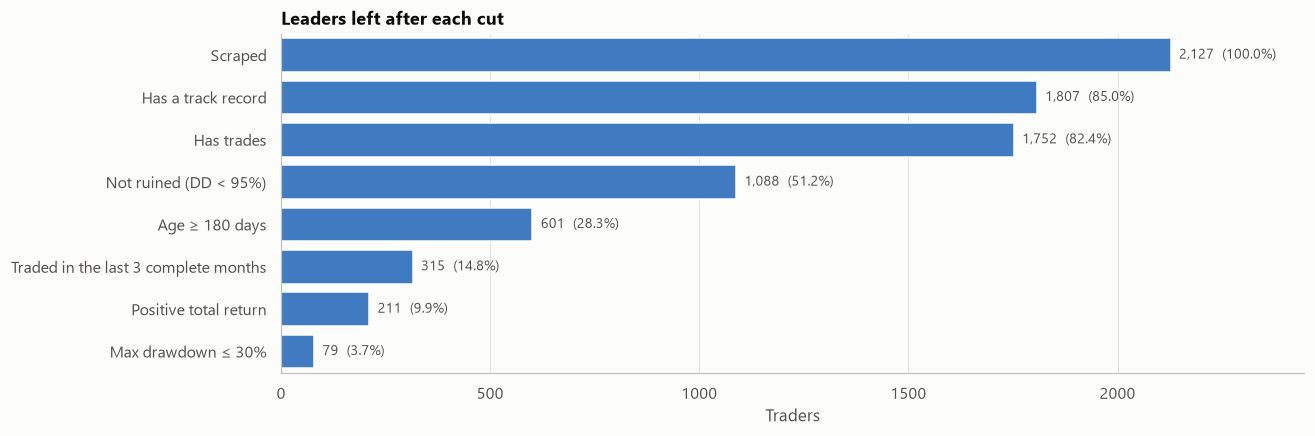

,step,traders,share_of_scraped
0,Scraped,2127,100.0
1,Has a track record,1807,85.0
2,Has trades,1752,82.4
3,Not ruined (DD < 95%),1088,51.2
4,Age ≥ 180 days,601,28.3
5,Traded in the last 3 complete months,315,14.8
6,Positive total return,211,9.9
7,Max drawdown ≤ 30%,79,3.7


In [19]:
funnel_df = pd.DataFrame(funnel, columns=["step", "traders"])
funnel_df["share_of_scraped"] = (100 * funnel_df["traders"] / funnel_df["traders"].iloc[0]).round(1)

fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(data=funnel_df, y="step", x="traders", color=ps.PRIMARY, ax=ax)
for y, (n, share) in enumerate(zip(funnel_df["traders"], funnel_df["share_of_scraped"])):
    ax.text(n + 20, y, f"{n:,}  ({share}%)", va="center", color=ps.INK_SECONDARY, fontsize=9)
ax.set_title("Leaders left after each cut")
ax.set_xlabel("Traders")
ax.set_ylabel("")
ax.set_xlim(0, funnel_df["traders"].iloc[0] * 1.15)
plt.show()
funnel_df

**Insights:**
- Of 2,127 scraped leaders, only **79 (3.7%)** are left.
- Besides the 320 new accounts dropped first, the cuts in order of size were ruin (664), track records under 180 days (487), inactivity (286), max drawdown above 30% (132), losses since inception (104) and no trades (55).
- Every section below describes these 79 traders. The comparisons are on median CAGR and drawdown, because no one here is ruined or losing.

## 6. Trading style: frequency and trade duration

Trades per day = `total_instrument_trades / age_days` (01 explains why the instruments count is used). Average trade duration comes from the trade statistics, converted to hours in 01. With ruined and losing accounts gone, each group is compared on median CAGR and median drawdown.

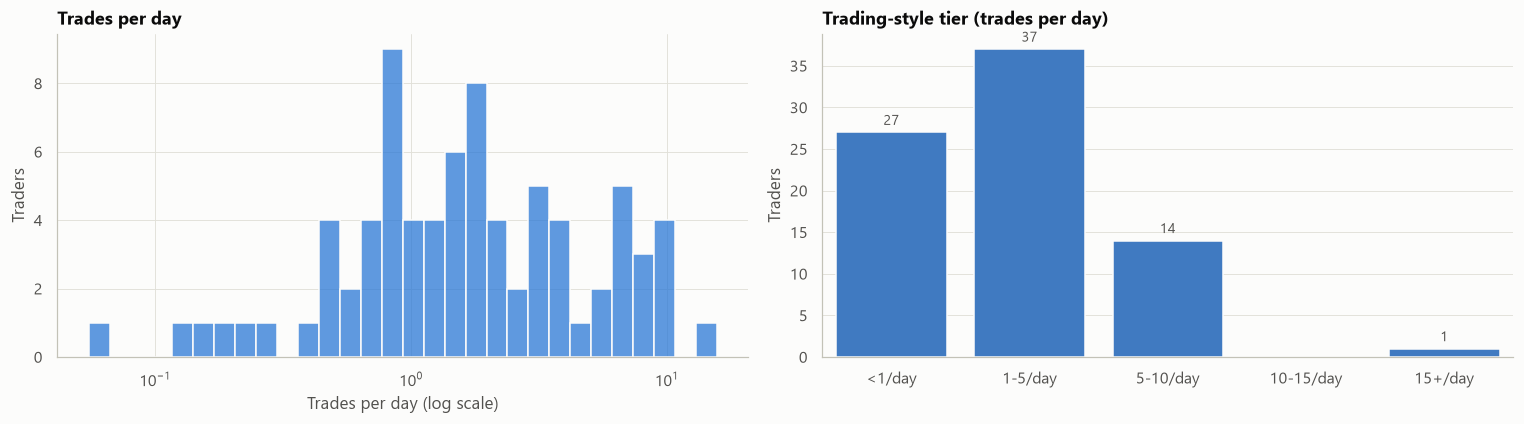

,traders,median_cagr,median_dd
style_tier,,,
<1/day,27,37.1,21.2
1-5/day,37,39.8,17.7
5-10/day,14,51.9,22.9
15+/day,1,18.4,20.4


In [20]:
tier_stats = df.groupby("style_tier", observed=True).agg(
    traders=("trader_id", "size"),
    median_cagr=("cagr_pct", "median"),
    median_dd=("trading_max_drawdown", "median"),
).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="trades_per_day", log_scale=True, bins=30, color=ps.PRIMARY, ax=axes[0])
axes[0].set_title("Trades per day")
axes[0].set_xlabel("Trades per day (log scale)")
axes[0].set_ylabel("Traders")
sns.countplot(data=df, x="style_tier", order=STYLE_LABELS, color=ps.PRIMARY, ax=axes[1])
ps.label_bars(axes[1])
axes[1].set_title("Trading-style tier (trades per day)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Traders")
plt.tight_layout()
plt.show()
tier_stats

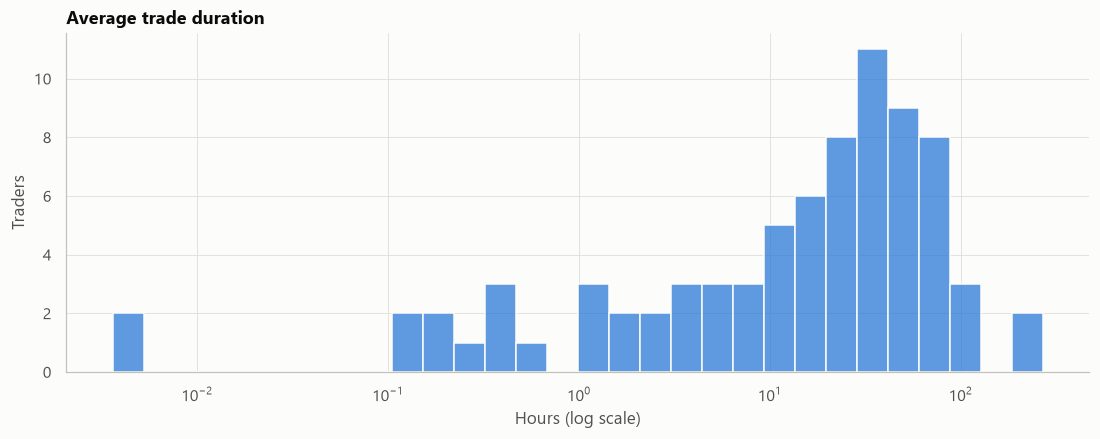

,traders,median_cagr,median_dd
duration_bucket,,,
<15 min,6,63.6,15.1
15-60 min,5,108.9,21.2
1-8 h,13,69.4,19.5
8-24 h,18,30.3,15.2
1-7 d,35,32.5,21.8
> 1 wk,2,39.2,18.2


In [21]:
duration_labels = ["<15 min", "15-60 min", "1-8 h", "8-24 h", "1-7 d", "> 1 wk"]
df["duration_bucket"] = pd.cut(df["ts_avg_duration_hours"], [0, 0.25, 1, 8, 24, 168, np.inf], labels=duration_labels)
duration_stats = df.groupby("duration_bucket", observed=True).agg(
    traders=("trader_id", "size"),
    median_cagr=("cagr_pct", "median"),
    median_dd=("trading_max_drawdown", "median"),
).round(1)

fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=df, x="ts_avg_duration_hours", log_scale=True, bins=30, color=ps.PRIMARY, ax=ax)
ax.set_title("Average trade duration")
ax.set_xlabel("Hours (log scale)")
ax.set_ylabel("Traders")
plt.show()
duration_stats

**Insights:**
- Cleaning took out almost every high-frequency trader. Of the 222 accounts doing 10+ trades a day before cleaning, **1** is left. The 79 traders are 27 below 1 trade a day, 37 at 1-5 and 14 at 5-10.
- Across the tiers that remain, median CAGR (+37% to +52%) and median drawdown (18-23%) are similar, so frequency doesn't separate the good leaders from each other. Its value was in screening out the ones that blow up (§1).
- 35 of the 79 hold trades for 1-7 days on average. The short-duration groups show higher median CAGR, but with only 5-13 traders each.

## 7. Win rate vs payoff

Win rate on its own is misleading: a strategy that closes winners fast and lets losers run (grid, martingale, no stop-loss) shows a very high win rate right up until one loss wipes it out. The breakeven curve `payoff = (1 − p) / p` separates strategies with a positive edge (above it) from those that lose on average (below it). Both axes are ratios of amounts in the same account currency, so currency doesn't matter.

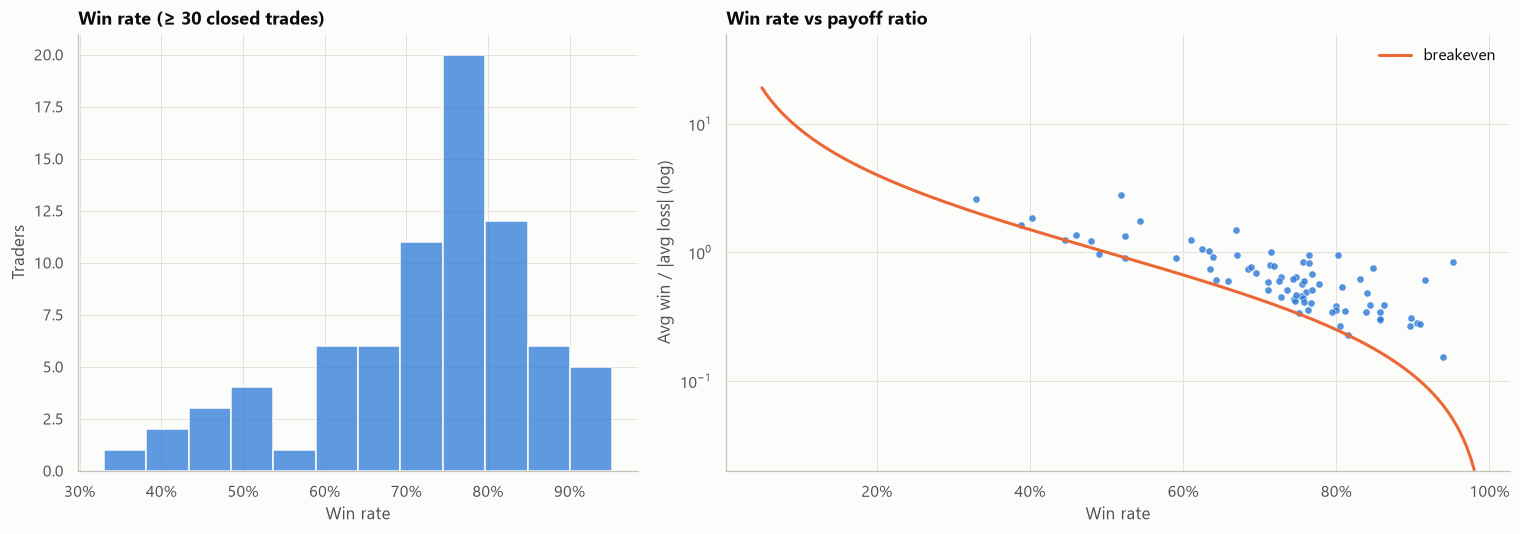

Traders with ≥ 30 closed trades: 77; median win rate 75%; rank correlation win rate vs payoff -0.76


,traders,edge_positive_pct,median_payoff,median_cagr
win_rate,,,,
"[0.0, 0.5)",7,71.43,1.37,9.28
"[0.5, 0.6)",5,80.00,1.34,54.59
"[0.6, 0.7)",12,100.00,0.84,76.80
"[0.7, 0.8)",31,100.00,0.51,39.64
"[0.8, 1.0)",22,100.00,0.35,38.45


In [22]:
wr = df[df["closed_trades"] >= 30].copy()
wr["win_rate_pct"] = 100 * wr["win_rate"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})
sns.histplot(data=wr, x="win_rate_pct", binwidth=5, color=ps.PRIMARY, ax=axes[0])
axes[0].set_title("Win rate (≥ 30 closed trades)")
axes[0].set_xlabel("Win rate")
axes[0].xaxis.set_major_formatter(ps.percent_formatter)
axes[0].set_ylabel("Traders")

sns.scatterplot(data=wr, x="win_rate_pct", y="payoff_ratio", color=ps.PRIMARY, s=22, alpha=0.8, ax=axes[1])
p = np.linspace(0.05, 0.98, 200)
sns.lineplot(x=100 * p, y=(1 - p) / p, color=ps.HIGHLIGHT, label="breakeven", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_ylim(0.02, 50)
axes[1].set_title("Win rate vs payoff ratio")
axes[1].set_xlabel("Win rate")
axes[1].set_ylabel("Avg win / |avg loss| (log)")
axes[1].xaxis.set_major_formatter(ps.percent_formatter)
axes[1].legend(title="", loc="upper right")
plt.tight_layout()
plt.show()

wr["edge_positive"] = wr["win_rate"] * wr["payoff_ratio"] > (1 - wr["win_rate"])
print(f"Traders with ≥ 30 closed trades: {len(wr)}; median win rate {wr['win_rate'].median():.0%}; "
      f"rank correlation win rate vs payoff {wr[['win_rate', 'payoff_ratio']].rank().corr().iloc[0, 1]:.2f}")
win_bins = pd.cut(wr["win_rate"], [0, 0.5, 0.6, 0.7, 0.8, 1.0001], right=False)
wr.groupby(win_bins, observed=True).agg(
    traders=("trader_id", "size"),
    edge_positive_pct=("edge_positive", lambda s: 100 * s.mean()),
    median_payoff=("payoff_ratio", "median"),
    median_cagr=("cagr_pct", "median"),
).round(2)

**Insights:**
- The median win rate is **75%**, and win rate and payoff ratio still move in opposite directions (rank correlation −0.76): strategies that win more often win smaller amounts per trade.
- Every trader with a win rate above 60% has a positive closed-trade edge, as expected for profitable accounts. Win rate doesn't order CAGR either: the 60-70% bucket has the highest median (+77%), and higher win rates earn about half of that.
- 03 uses currency-free trade metrics (profit factor, expectancy in R) alongside drawdown-based risk metrics, not win rate on its own.

## 8. Instruments and asset classes

Uses the normalized instruments from 01 (account-type suffixes folded, so `XAUUSDxr` and `XAUUSD` count as one market) and each trader's primary asset class.

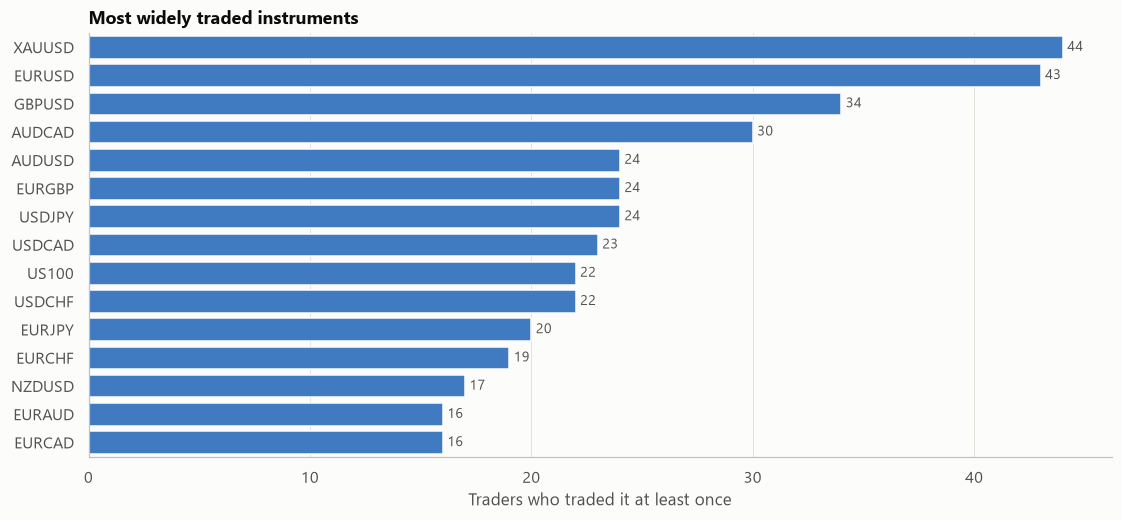

,traders,trades,share_of_all_trades_pct
XAUUSD,44,20704.0,17.6
EURUSD,43,22134.0,18.8
GBPUSD,34,5239.0,4.4
AUDCAD,30,17129.0,14.5
AUDUSD,24,573.0,0.5
EURGBP,24,7100.0,6.0
USDJPY,24,2629.0,2.2
USDCAD,23,1562.0,1.3
US100,22,8241.0,7.0
USDCHF,22,1307.0,1.1


In [23]:
traders_per_symbol = pd.Series([s for d in df["instruments_normalized"] for s in d]).value_counts()
trades_per_symbol = pd.DataFrame(df["instruments_normalized"].tolist()).sum()
top_symbols = pd.DataFrame({"traders": traders_per_symbol, "trades": trades_per_symbol}).nlargest(15, "traders")
top_symbols["share_of_all_trades_pct"] = (100 * top_symbols["trades"] / trades_per_symbol.sum()).round(1)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=top_symbols["traders"], y=top_symbols.index, color=ps.PRIMARY, ax=ax)
ps.label_bars(ax)
ax.set_title("Most widely traded instruments")
ax.set_xlabel("Traders who traded it at least once")
ax.set_ylabel("")
plt.show()
top_symbols

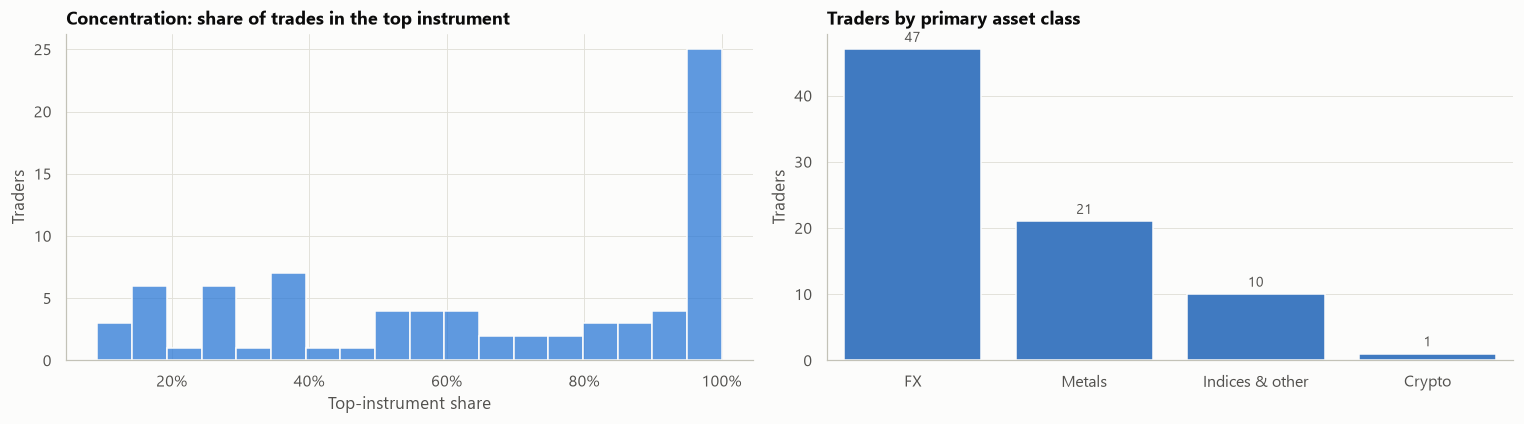

Trade ≥ 80% in one instrument: 44.3%
Gold is the main instrument for 27.8% of traders


,traders,median_cagr,median_dd
primary_asset_class,,,
FX,47,39.6,20.9
Metals,21,70.3,18.8
Indices & other,10,16.7,20.1
Crypto,1,29.3,6.1


In [24]:
asset_stats = df.groupby("primary_asset_class").agg(
    traders=("trader_id", "size"),
    median_cagr=("cagr_pct", "median"),
    median_dd=("trading_max_drawdown", "median"),
).sort_values("traders", ascending=False).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(x=100 * df["top_instrument_share"], binwidth=5, color=ps.PRIMARY, ax=axes[0])
axes[0].set_title("Concentration: share of trades in the top instrument")
axes[0].set_xlabel("Top-instrument share")
axes[0].xaxis.set_major_formatter(ps.percent_formatter)
axes[0].set_ylabel("Traders")

sns.barplot(x=asset_stats.index, y=asset_stats["traders"], color=ps.PRIMARY, ax=axes[1])
ps.label_bars(axes[1])
axes[1].set_title("Traders by primary asset class")
axes[1].set_xlabel("")
axes[1].set_ylabel("Traders")
plt.tight_layout()
plt.show()

print(f"Trade ≥ 80% in one instrument: {(df['top_instrument_share'] >= 0.8).mean():.1%}")
print(f"Gold is the main instrument for {(df['top_instrument'] == 'XAUUSD').mean():.1%} of traders")
asset_stats

In [25]:
concentration = pd.cut(df["top_instrument_share"], [0, 0.5, 0.8, 0.99, 1.0],
                       labels=["< 50%", "50-80%", "80-99%", "single instrument"])
df.groupby(concentration, observed=True).agg(
    traders=("trader_id", "size"),
    median_cagr=("cagr_pct", "median"),
    median_dd=("trading_max_drawdown", "median"),
).round(1)

,traders,median_cagr,median_dd
top_instrument_share,,,
< 50%,26,38.4,21.9
50-80%,18,27.9,21.4
80-99%,13,41.7,21.4
single instrument,22,54.9,16.9


**Insights:**
- The gold monoculture of the full leaderboard mostly disappears. Gold is the main instrument for only **28%** of the cleaned traders (70% before cleaning), and **FX** is the main asset class for 47 of 79.
- Gold traders who survived do well: median CAGR **+70%** against +40% for FX, at a similar median drawdown (19% vs 21%).
- Concentration is lower too: 44% trade ≥ 80% in one instrument (66% before cleaning). Single-instrument traders have the highest median CAGR (+55%) and the lowest drawdown (17%).
- AUDCAD is 14.5% of all trades from only 30 traders, so a few high-frequency AUDCAD strategies are behind that volume. Leaders that trade the same pair are likely to be correlated (see the correlation check in 03).

## 9. Leverage

Uses the leverage summaries from 01 (computed on days with open exposure). §1 showed that high leverage came with ruin across the whole universe; here the question is whether it still explains drawdown among the traders that are left. Leverage is split into quintiles, and a violin plot shows each quintile's full drawdown distribution, not just the median.

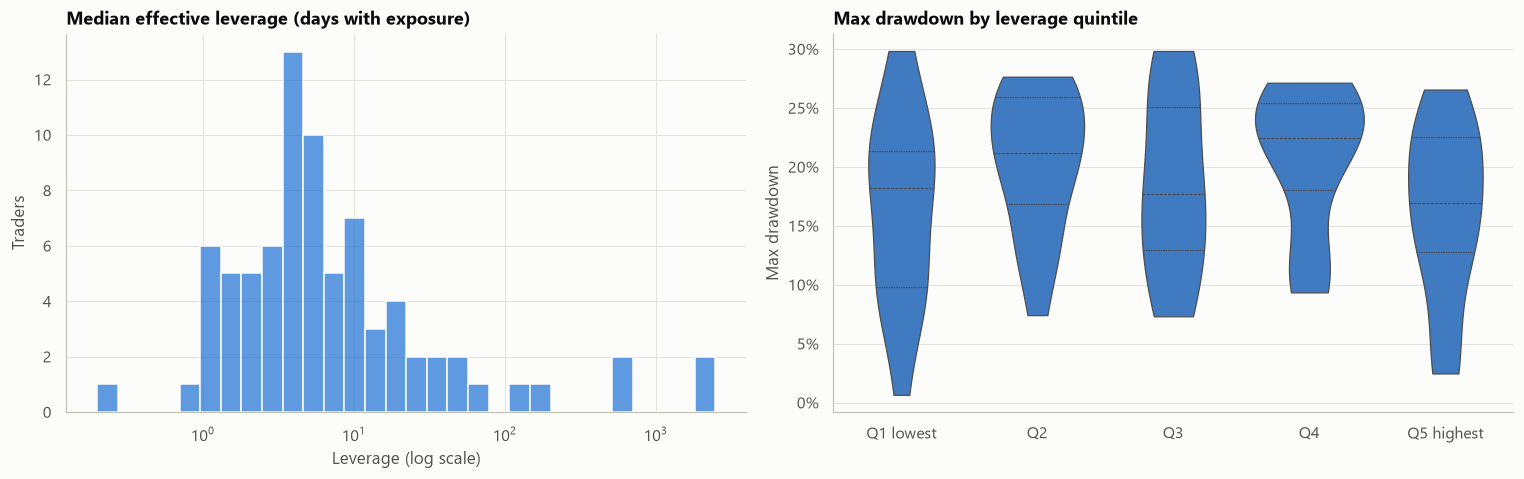

,leverage_range,traders,median_dd,median_cagr
lev_quintile,,,,
Q1 lowest,0.2-2x,16,18.2,18.8
Q2,2.2-4x,16,21.2,40.7
Q3,4.2-6x,15,17.7,50.4
Q4,6.8-17x,16,22.4,69.9
Q5 highest,"18.4-2,488x",16,16.9,27.2


,lev_median,lev_p95,trading_max_drawdown
lev_median,1.00,0.78,-0.01
lev_p95,0.78,1.00,-0.01
trading_max_drawdown,-0.01,-0.01,1.00


In [26]:
lev = df[df["lev_median"] > 0].copy()
lev["lev_quintile"] = pd.qcut(lev["lev_median"], 5, labels=LEV_QUINTILES)
lev_stats = lev.groupby("lev_quintile", observed=True).agg(
    leverage_range=("lev_median", lambda s: f"{s.min():.1f}-{s.max():,.0f}x"),
    traders=("trader_id", "size"),
    median_dd=("trading_max_drawdown", "median"),
    median_cagr=("cagr_pct", "median"),
).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=lev, x="lev_median", log_scale=True, bins=30, color=ps.PRIMARY, ax=axes[0])
axes[0].set_title("Median effective leverage (days with exposure)")
axes[0].set_xlabel("Leverage (log scale)")
axes[0].set_ylabel("Traders")
sns.violinplot(data=lev, x="lev_quintile", y="trading_max_drawdown", color=ps.SERIES[0], cut=0,
               inner="quartile", linewidth=0.8, ax=axes[1])
axes[1].set_title("Max drawdown by leverage quintile")
axes[1].set_xlabel("")
axes[1].set_ylabel("Max drawdown")
axes[1].yaxis.set_major_formatter(ps.percent_formatter)
plt.tight_layout()
plt.show()
display(lev_stats)
lev[["lev_median", "lev_p95", "trading_max_drawdown"]].rank().corr().round(2)

**Insights:**
- The cleaned traders use much less leverage: **5.5x** median on days with exposure (Q1-Q4 span 0.2x to 17x), compared with 10-100x for the full leaderboard.
- Inside the cleaned set leverage no longer explains drawdown (ρ = −0.01), because the 30% cap cuts the drawdown range short. Median CAGR rises with leverage up to Q4 (+70%) and drops in Q5 (+27%).
- A few extreme values remain (up to 2,488x median). p95 leverage stays a risk input in 03 because of what §1 showed about ruin.

## 10. Monthly returns over calendar time

Pooling every trader's monthly return by calendar month shows whether results are driven by market regimes (for example a gold trend) rather than individual skill. Only months in which the trader actually traded count (a 0.00% month means a dormant account), and only calendar months with at least `MIN_TRADERS_PER_MONTH` such traders are shown. Every trader here survived the cuts in §1-4, so this view is survivor-biased by construction.

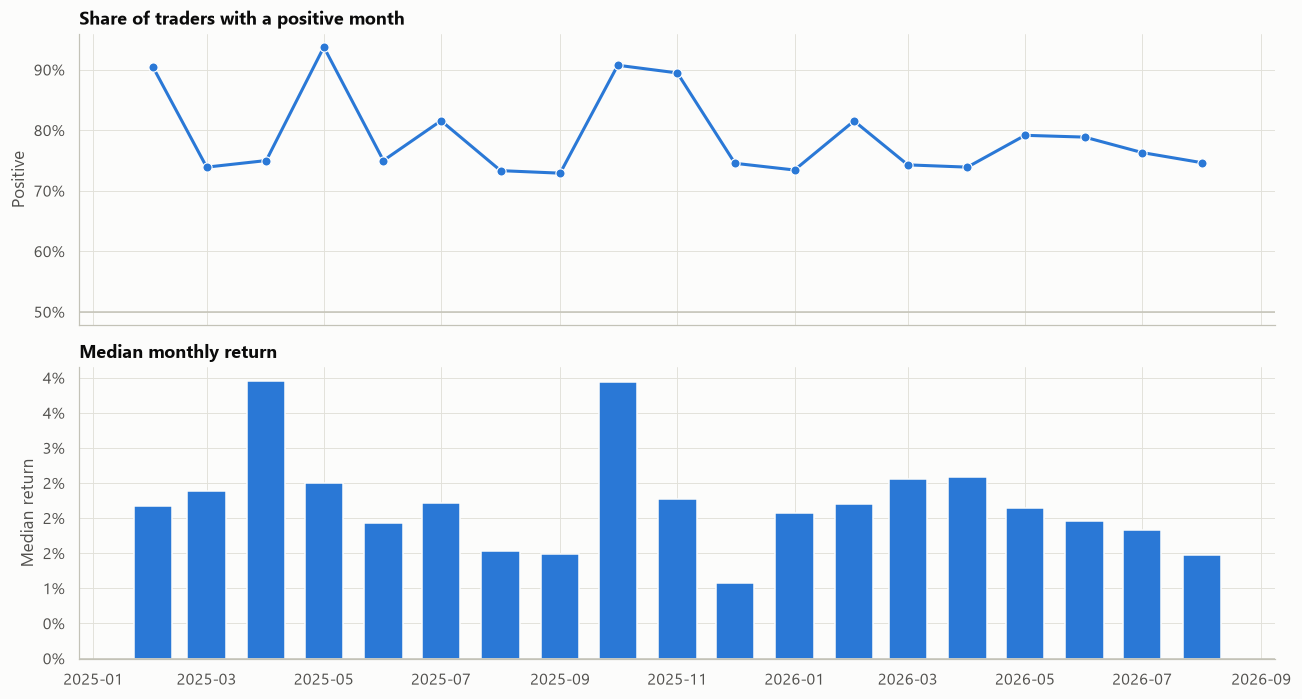

,traders,positive_pct,median_ret_pct
month,,,
2025-09,48,72.9,1.5
2025-10,54,90.7,3.9
2025-11,57,89.5,2.3
2025-12,55,74.5,1.1
2026-01,64,73.4,2.1
2026-02,65,81.5,2.2
2026-03,70,74.3,2.6
2026-04,69,73.9,2.6
2026-05,72,79.2,2.1


In [27]:
MIN_TRADERS_PER_MONTH = 20
monthly_long = pd.DataFrame(
    [(tid, month, value) for tid, returns in zip(df["trader_id"], df["monthly_returns"]) for month, value in returns.items()],
    columns=["trader_id", "month", "ret"],
)
monthly_long = monthly_long[monthly_long["month"] < SNAPSHOT]  # the snapshot month has only partly elapsed
traded_months = monthly_long[monthly_long["ret"] != 0]

by_month = traded_months.groupby("month").agg(
    traders=("ret", "size"),
    positive_pct=("ret", lambda s: 100 * (s > 0).mean()),
    median_ret_pct=("ret", lambda s: 100 * s.median()),
)
by_month = by_month[by_month["traders"] >= MIN_TRADERS_PER_MONTH].reset_index()
by_month["month_start"] = by_month["month"].dt.to_timestamp()
by_month["sign"] = np.where(by_month["median_ret_pct"] >= 0, "gain", "loss")

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
sns.lineplot(data=by_month, x="month_start", y="positive_pct", marker="o", color=ps.PRIMARY, ax=axes[0])
axes[0].axhline(50, color=ps.BASELINE, linewidth=1)
axes[0].set_title("Share of traders with a positive month")
axes[0].set_ylabel("Positive")
axes[0].yaxis.set_major_formatter(ps.percent_formatter)
axes[1].bar(by_month["month_start"], by_month["median_ret_pct"], width=20,
            color=[ps.SERIES[0] if s == "gain" else ps.SERIES[7] for s in by_month["sign"]])
axes[1].axhline(0, color=ps.BASELINE, linewidth=1)
axes[1].set_title("Median monthly return")
axes[1].set_ylabel("Median return")
axes[1].set_xlabel("")
axes[1].yaxis.set_major_formatter(ps.percent_formatter)
plt.tight_layout()
plt.show()
by_month.drop(columns=["month_start", "sign"]).set_index("month").tail(12).round(1)

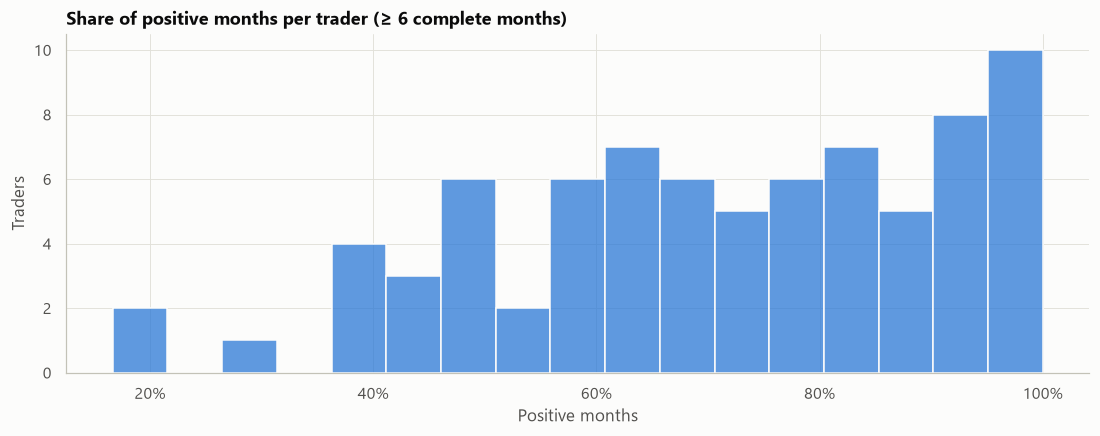

,count,mean,std,min,25%,50%,75%,max
positive_share,78.0,0.71,0.21,0.17,0.57,0.74,0.88,1.0


In [28]:
# Each trader's share of positive months (complete months only, at least 6). Dormant 0% months count as not positive.
per_trader = monthly_long.groupby("trader_id")["ret"].agg(months="size", positive_share=lambda s: (s > 0).mean())
per_trader = per_trader[per_trader["months"] >= 6]

fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(x=100 * per_trader["positive_share"], binwidth=5, color=ps.PRIMARY, ax=ax)
ax.set_title("Share of positive months per trader (≥ 6 complete months)")
ax.set_xlabel("Positive months")
ax.xaxis.set_major_formatter(ps.percent_formatter)
ax.set_ylabel("Traders")
plt.show()
per_trader["positive_share"].describe().round(2).to_frame().T

**Insights:**
- In every calendar month shown, **73-91%** of the cleaned traders who traded had a positive month, with median monthly returns between +1.1% and +3.9%. October 2025 was the best month and December 2025 the weakest.
- Per trader, the median share of positive complete months is **74%**.
- **Survivorship bias is built in:** every trader here had to be profitable, active and below 30% drawdown at the snapshot. This is a picture of what the selected leaders look like, not an estimate of what copying them will return. 03's out-of-sample test is the place for that.

## 11. Account currency

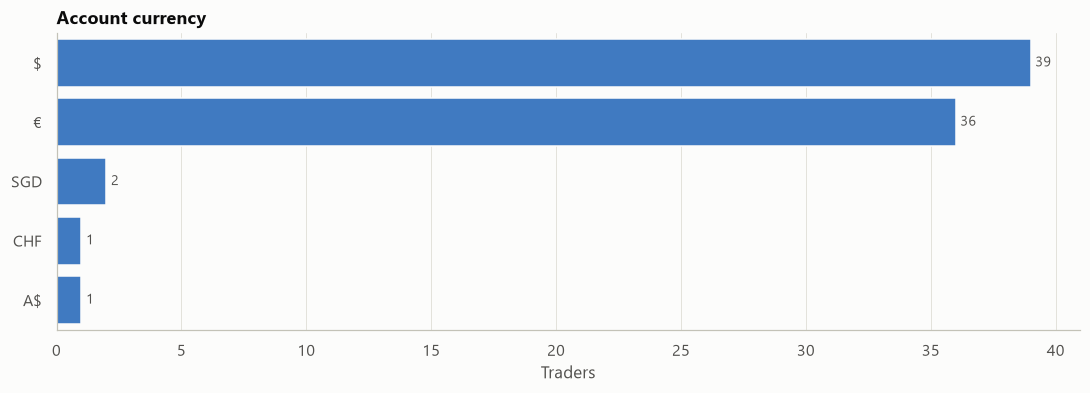

In [29]:
currency_counts = df["currency"].value_counts().reset_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.barplot(data=currency_counts, y="currency", x="count", color=ps.PRIMARY, ax=ax)
ps.label_bars(ax)
ax.set_title("Account currency")
ax.set_xlabel("Traders")
ax.set_ylabel("")
plt.show()

**Insights:**
- Accounts are mostly in USD (39) and EUR (36), plus 2 SGD, 1 CHF and 1 AUD. Monetary fields (`Total profit`, average win/loss, best/worst trade) are **not comparable across traders** without FX conversion. Ratios of same-currency amounts (profit factor, payoff, expectancy in R) are, which is why 03 builds on those.

## 12. How the metrics relate to each other

Spearman (rank) correlation on the cleaned traders with ≥ 30 closed trades. Ranks are robust to the extreme outliers this data is full of. Strongly correlated metrics carry the same information and shouldn't be double-counted in a score.

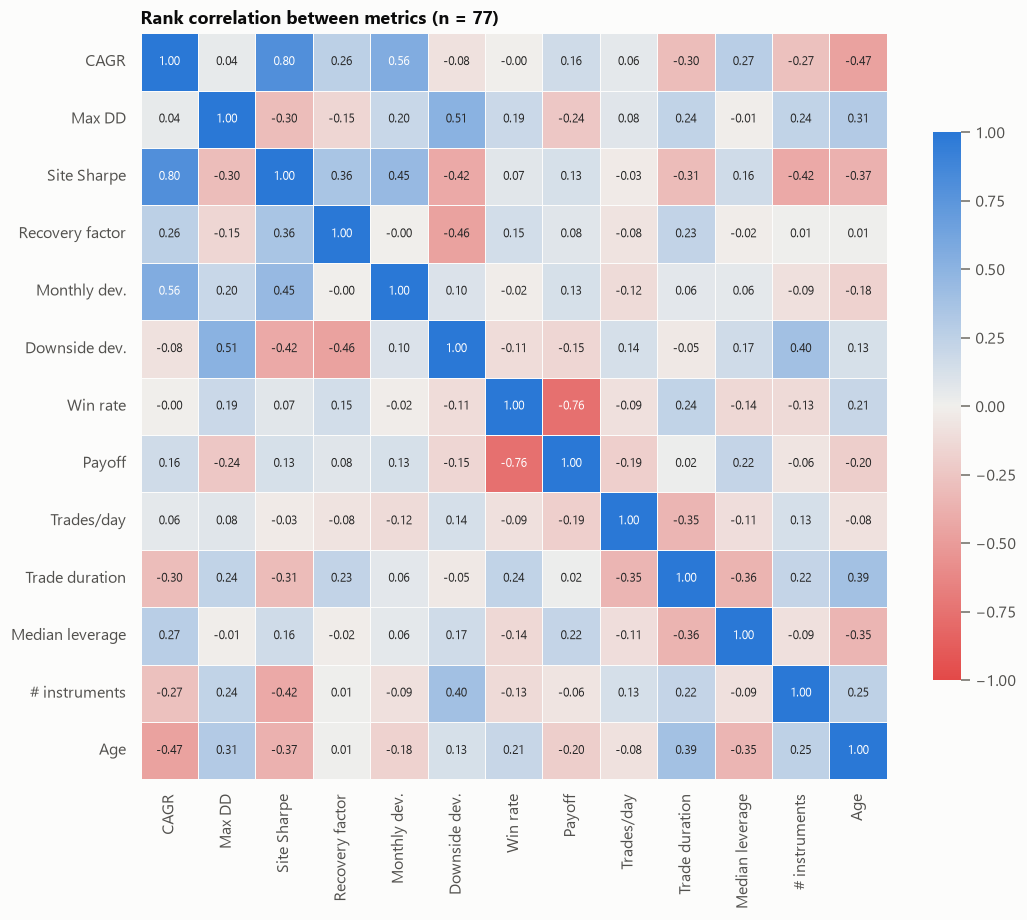

In [30]:
corr_cols = {
    "cagr_pct": "CAGR",
    "trading_max_drawdown": "Max DD",
    "trading_sharpe_ratio": "Site Sharpe",
    "trading_recovery_factor": "Recovery factor",
    "return_deviation_monthly": "Monthly dev.",
    "trading_downside_deviation": "Downside dev.",
    "win_rate": "Win rate",
    "payoff_ratio": "Payoff",
    "trades_per_day": "Trades/day",
    "ts_avg_duration_hours": "Trade duration",
    "lev_median": "Median leverage",
    "num_instruments_traded": "# instruments",
    "age_days": "Age",
}
sample = df[df["closed_trades"] >= 30]
corr = sample[list(corr_cols)].rank().corr()
corr.index = corr.columns = list(corr_cols.values())

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, cmap=ps.DIVERGING_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, square=True, linewidths=0.5, linecolor=ps.SURFACE,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title(f"Rank correlation between metrics (n = {len(sample)})")
plt.tight_layout()
plt.show()

**Insights:**
- The site's **Sharpe ratio is close to a pure return ranking** (ρ = 0.80 with CAGR) and only weakly penalizes drawdown (−0.30).
- Downside deviation and max drawdown carry largely the same signal (ρ = 0.51). A score that sums all of them counts the same thing several times. 03 groups metrics by what they measure (return, risk, consistency, trade edge) and weights the groups.
- **Younger leaders show a higher CAGR** (ρ = −0.47 with age). Short records annualize big early runs, which is one more reason 03 separates established leaders from the watchlist.
- Leverage falls with trade duration (−0.36) and with account age (−0.35): older, slower accounts use less leverage.

### `return_deviation_monthly` reliability

A deviation of exactly 0 means every month had the same return. The share of such values and the agreement with the monthly standard deviation recomputed from the monthly return series (rank correlation) are printed below. In the full leaderboard 64% of the values were exactly 0 and the agreement was only 0.11, because most of the zeros came from dormant and ruined accounts. Among the cleaned traders it's better, but still only moderate, so 03 recomputes volatility from the monthly return series instead.

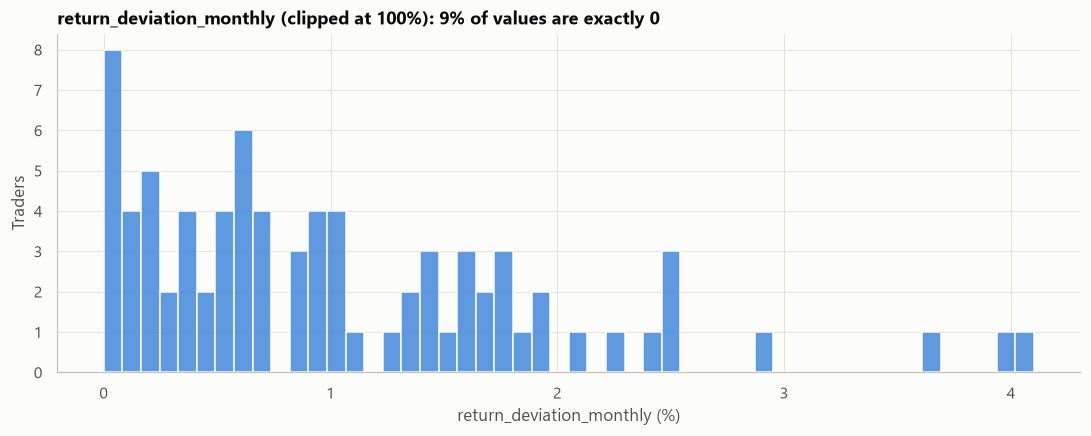

Rank correlation, site value vs monthly std recomputed from the chart: 0.46


In [31]:
zero_share = (df["return_deviation_monthly"] == 0).mean()
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(x=df["return_deviation_monthly"].clip(upper=100), bins=50, color=ps.PRIMARY, ax=ax)
ax.set_title(f"return_deviation_monthly (clipped at 100%): {zero_share:.0%} of values are exactly 0")
ax.set_xlabel("return_deviation_monthly (%)")
ax.set_ylabel("Traders")
plt.show()

compare = df[df["n_months"] >= 3].copy()
compare["recomputed_monthly_std"] = compare["monthly_returns"].apply(lambda r: 100 * r.std(ddof=1))
print(f"Rank correlation, site value vs monthly std recomputed from the chart: "
      f"{compare[['return_deviation_monthly', 'recomputed_monthly_std']].rank().corr().iloc[0, 1]:.2f}")

## 13. Summary and further analysis

**What the data says about FP Markets leaders**
1. **Most leaders aren't worth copying.** Only 79 of 2,127 scraped leaders (3.7%) have a track record of at least 180 days, traded in the last 3 complete months, are profitable and stayed below a 30% drawdown.
2. **Ruin is the biggest filter.** 38% of accounts that have traded have a drawdown of 95% or more. Their post-ruin % returns are artifacts that push them to the top of the site's leaderboard.
3. **High leverage and high trading frequency came with ruin.** 58% of accounts above 99x median leverage are ruined, against 9% at ≤ 12x. Only 1 trader doing 10+ trades a day survived the cleaning.
4. **Many listed leaders are idle.** The site pads stopped accounts with 0% months, so activity has to be judged from the last non-zero month: 48% of the mature, non-ruined accounts haven't traded in 3 months.
5. **The cleaned traders are a different population:** mostly FX, at a median 5.5x leverage, about 1.6 trades a day and multi-hour to multi-day holds. Gold leaders are a minority but earn the most.
6. **Win rate is still a trap.** It's strongly anti-correlated with payoff (−0.76) and doesn't order returns.
7. **Everything after §5 is survivor-biased** by construction. The selected leaders look good partly because they were selected for looking good at the snapshot.

**Further analysis this dataset supports (not done here):**
- **Persistence / out-of-sample test.** Re-scrape monthly and check whether leaders ranked highly at time *t* still do well at *t* + 3 months. This is the only real validation of any ranking, and the scraper is already resumable enough to build such a panel.
- **Time-to-ruin survival curves (Kaplan-Meier).** Date each blow-up from the first month the compounded equity falls below 5% of its peak, instead of using the snapshot age.
- **Leverage as an early warning.** Check whether leverage spikes in `leverage_chart` come before blow-ups, which would let a copier exit before ruin.
- **Style clustering.** k-means on frequency, duration, leverage, concentration and win rate to name the archetypes (FX swing, gold intraday, index bot).
- **Return correlation between candidates** to build a diversified shortlist (a first version is in 03).
- **FX-normalize monetary fields** to compare account size and P&L per lot across currencies.
- **Cross-broker comparison** with the Binance dataset using the shared metric functions in `analysis/shared/performance_metrics.py`.

## 14. Export

Save the cleaned traders (§5), with the flags and the trading-style tier from §1, for `03_strategy_metrics.ipynb`. The helper columns used only for the charts here are left out. As in 01, there are two copies:
- **`analysis/data/fpmarkets_flagged.pkl`**: what 03 reads, with every type kept.
- **`analysis/data/fpmarkets_flagged.csv`**: the same data for opening without pandas. Dict and series cells are written as JSON.

In [32]:
def csv_friendly(frame: pd.DataFrame) -> pd.DataFrame:
    """JSON-encode dict and Series cells (instrument counts, monthly returns) so the CSV copy stays readable."""
    out = frame.copy()
    for col in out.columns[out.dtypes == object]:
        sample = out[col].dropna()
        if len(sample) and isinstance(sample.iloc[0], (dict, pd.Series)):
            out[col] = out[col].apply(lambda v: json.dumps(
                {str(k): round(x, 8) if isinstance(x, float) else x for k, x in v.items()}))
    return out


flagged = df.drop(columns=HELPER_COLUMNS + ["return_bucket", "duration_bucket"])
flagged.to_pickle(OUT_PKL)
csv_friendly(flagged).to_csv(OUT_CSV, index=False)
print(f"Saved {flagged.shape[0]} rows x {flagged.shape[1]} cols -> {OUT_PKL} (+ {OUT_CSV.name})")

Saved 79 rows x 66 cols -> ..\data\fpmarkets_flagged.pkl (+ fpmarkets_flagged.csv)
